# Bài thực hành Logistic Regression và Softmax Regression


## Chuẩn bị dữ liệu MNIST


In [1]:
import gzip
import struct
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


np.random.seed(42)


thu_muc_du_lieu = Path("mnist_data")
thu_muc_du_lieu.mkdir(exist_ok=True)

duong_dan_goc = "https://storage.googleapis.com/cvdf-datasets/mnist/"
ten_file = {
    "x_train": "train-images-idx3-ubyte.gz",
    "y_train": "train-labels-idx1-ubyte.gz",
    "x_test": "t10k-images-idx3-ubyte.gz",
    "y_test": "t10k-labels-idx1-ubyte.gz",
}


def tai_du_lieu():
    for file in ten_file.values():
        noi_luu = thu_muc_du_lieu / file
        if not noi_luu.exists():
            print("Đang tải:", file)
            urllib.request.urlretrieve(duong_dan_goc + file, noi_luu)


def doc_anh(file):
    with gzip.open(file, "rb") as f:
        magic, so_anh, so_hang, so_cot = struct.unpack(">IIII", f.read(16))
        if magic != 2051:
            raise ValueError("File ảnh MNIST không hợp lệ")
        du_lieu = np.frombuffer(f.read(), dtype=np.uint8)
        return du_lieu.reshape(so_anh, so_hang * so_cot)


def doc_nhan(file):
    with gzip.open(file, "rb") as f:
        magic, so_nhan = struct.unpack(">II", f.read(8))
        if magic != 2049:
            raise ValueError("File nhãn MNIST không hợp lệ")
        return np.frombuffer(f.read(), dtype=np.uint8)


tai_du_lieu()

X_train = doc_anh(thu_muc_du_lieu / ten_file["x_train"]).astype(np.float32) / 255.0
y_train = doc_nhan(thu_muc_du_lieu / ten_file["y_train"])
X_test = doc_anh(thu_muc_du_lieu / ten_file["x_test"]).astype(np.float32) / 255.0
y_test = doc_nhan(thu_muc_du_lieu / ten_file["y_test"])

print("Kích thước tập train:", X_train.shape)
print("Kích thước tập test :", X_test.shape)


Kích thước tập train: (60000, 784)
Kích thước tập test : (10000, 784)


In [2]:
def danh_gia_nhi_phan(y_that, y_du_doan):
    tp = np.sum((y_that == 1) & (y_du_doan == 1))
    fp = np.sum((y_that == 0) & (y_du_doan == 1))
    fn = np.sum((y_that == 1) & (y_du_doan == 0))

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
    accuracy = np.mean(y_that == y_du_doan)

    return accuracy, precision, recall, f1


def danh_gia_nhieu_lop(y_that, y_du_doan):
    precision_cac_lop = []
    recall_cac_lop = []
    f1_cac_lop = []

    for lop in range(10):
        tp = np.sum((y_that == lop) & (y_du_doan == lop))
        fp = np.sum((y_that != lop) & (y_du_doan == lop))
        fn = np.sum((y_that == lop) & (y_du_doan != lop))

        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

        precision_cac_lop.append(precision)
        recall_cac_lop.append(recall)
        f1_cac_lop.append(f1)

    accuracy = np.mean(y_that == y_du_doan)
    return (
        accuracy,
        np.mean(precision_cac_lop),
        np.mean(recall_cac_lop),
        np.mean(f1_cac_lop),
    )


def in_ket_qua(accuracy, precision, recall, f1):
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")


## Bài 1: Logistic Regression bằng NumPy



================ BÀI 1 ================
Epoch 01/15, loss = 0.022237
Epoch 02/15, loss = 0.014715
Epoch 03/15, loss = 0.011793
Epoch 04/15, loss = 0.010179
Epoch 05/15, loss = 0.009114
Epoch 06/15, loss = 0.008357
Epoch 07/15, loss = 0.007787
Epoch 08/15, loss = 0.007330


Epoch 09/15, loss = 0.006959
Epoch 10/15, loss = 0.006646
Epoch 11/15, loss = 0.006380


Epoch 12/15, loss = 0.006151
Epoch 13/15, loss = 0.005949
Epoch 14/15, loss = 0.005770
Epoch 15/15, loss = 0.005609

Kết quả Logistic Regression bằng NumPy:
Accuracy : 0.9995
Precision: 0.9991
Recall   : 1.0000
F1-score : 0.9996


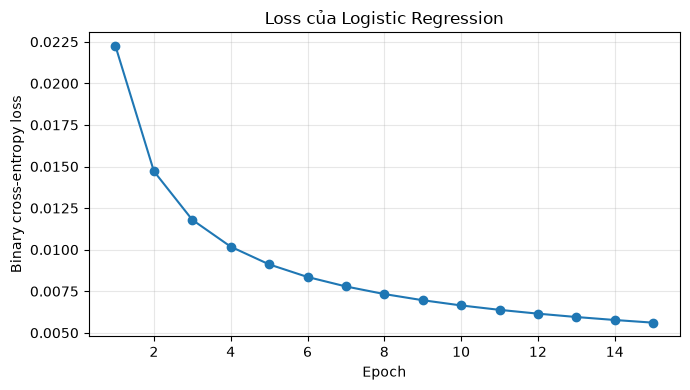

In [3]:
def sigmoid(z):
    z = np.clip(z, -40, 40)
    return 1 / (1 + np.exp(-z))


def train_logistic(X, y, learning_rate=0.2, so_epoch=15, batch_size=256):
    so_mau, so_thuoc_tinh = X.shape
    w = np.zeros(so_thuoc_tinh, dtype=np.float32)
    b = 0.0
    lich_su_loss = []

    for epoch in range(so_epoch):
        thu_tu = np.random.permutation(so_mau)

        for bat_dau in range(0, so_mau, batch_size):
            vi_tri = thu_tu[bat_dau:bat_dau + batch_size]
            X_batch = X[vi_tri]
            y_batch = y[vi_tri]

            y_xac_suat = sigmoid(X_batch @ w + b)
            sai_so = y_xac_suat - y_batch

            dao_ham_w = X_batch.T @ sai_so / len(vi_tri)
            dao_ham_b = np.mean(sai_so)

            w -= learning_rate * dao_ham_w
            b -= learning_rate * dao_ham_b

        y_xac_suat = sigmoid(X @ w + b)
        epsilon = 1e-8
        loss = -np.mean(
            y * np.log(y_xac_suat + epsilon)
            + (1 - y) * np.log(1 - y_xac_suat + epsilon)
        )
        lich_su_loss.append(loss)
        print(f"Epoch {epoch + 1:02d}/{so_epoch}, loss = {loss:.6f}")

    return w, b, lich_su_loss


print("\n================ BÀI 1 ================")

train_01 = np.isin(y_train, [0, 1])
test_01 = np.isin(y_test, [0, 1])

X_train_01 = X_train[train_01]
y_train_01 = y_train[train_01]
X_test_01 = X_test[test_01]
y_test_01 = y_test[test_01]

w_logistic, b_logistic, loss_logistic = train_logistic(X_train_01, y_train_01)

xac_suat_test = sigmoid(X_test_01 @ w_logistic + b_logistic)
y_du_doan_01 = (xac_suat_test >= 0.5).astype(np.uint8)

ket_qua_bai_1 = danh_gia_nhi_phan(y_test_01, y_du_doan_01)
print("\nKết quả Logistic Regression bằng NumPy:")
in_ket_qua(*ket_qua_bai_1)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_logistic) + 1), loss_logistic, marker="o")
plt.title("Loss của Logistic Regression")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_logistic.png", dpi=150)
plt.show()


## Bài 2: Softmax Regression bằng NumPy



================ BÀI 2 ================
Epoch 01/12, loss = 0.382797


Epoch 02/12, loss = 0.341831
Epoch 03/12, loss = 0.323001


Epoch 04/12, loss = 0.308509
Epoch 05/12, loss = 0.303417


Epoch 06/12, loss = 0.296015
Epoch 07/12, loss = 0.292726


Epoch 08/12, loss = 0.286420
Epoch 09/12, loss = 0.283255


Epoch 10/12, loss = 0.281528
Epoch 11/12, loss = 0.278555


Epoch 12/12, loss = 0.276099

Kết quả Softmax Regression bằng NumPy:
Accuracy : 0.9228
Precision: 0.9219
Recall   : 0.9218
F1-score : 0.9217


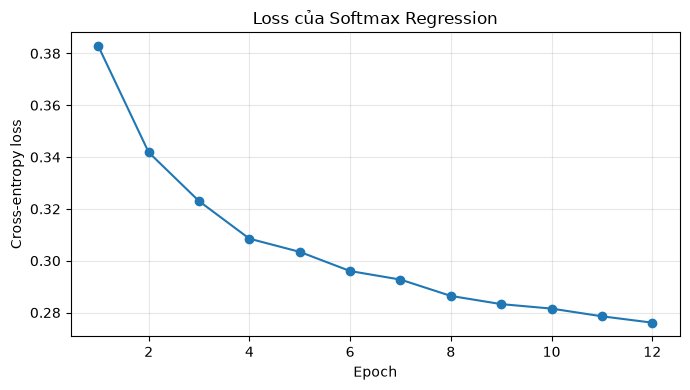

In [4]:
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def train_softmax(X, y, learning_rate=0.25, so_epoch=12, batch_size=256):
    so_mau, so_thuoc_tinh = X.shape
    so_lop = 10
    W = np.zeros((so_thuoc_tinh, so_lop), dtype=np.float32)
    b = np.zeros(so_lop, dtype=np.float32)
    lich_su_loss = []

    for epoch in range(so_epoch):
        thu_tu = np.random.permutation(so_mau)

        for bat_dau in range(0, so_mau, batch_size):
            vi_tri = thu_tu[bat_dau:bat_dau + batch_size]
            X_batch = X[vi_tri]
            y_batch = y[vi_tri]

            y_xac_suat = softmax(X_batch @ W + b)

            y_xac_suat[np.arange(len(vi_tri)), y_batch] -= 1
            y_xac_suat /= len(vi_tri)

            dao_ham_W = X_batch.T @ y_xac_suat
            dao_ham_b = np.sum(y_xac_suat, axis=0)

            W -= learning_rate * dao_ham_W
            b -= learning_rate * dao_ham_b

        y_xac_suat = softmax(X @ W + b)
        epsilon = 1e-8
        loss = -np.mean(np.log(y_xac_suat[np.arange(so_mau), y] + epsilon))
        lich_su_loss.append(loss)
        print(f"Epoch {epoch + 1:02d}/{so_epoch}, loss = {loss:.6f}")

    return W, b, lich_su_loss


print("\n================ BÀI 2 ================")

W_softmax, b_softmax, loss_softmax = train_softmax(X_train, y_train)
y_du_doan_softmax = np.argmax(softmax(X_test @ W_softmax + b_softmax), axis=1)

ket_qua_bai_2 = danh_gia_nhieu_lop(y_test, y_du_doan_softmax)
print("\nKết quả Softmax Regression bằng NumPy:")
in_ket_qua(*ket_qua_bai_2)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_softmax) + 1), loss_softmax, marker="o")
plt.title("Loss của Softmax Regression")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_softmax.png", dpi=150)
plt.show()


## Bài 3: Scikit-learn


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

print("================ BÀI 3 ================")

model_thu_vien_01 = LogisticRegression(max_iter=200, random_state=42)
model_thu_vien_01.fit(X_train_01, y_train_01)
y_du_doan_thu_vien_01 = model_thu_vien_01.predict(X_test_01)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test_01, y_du_doan_thu_vien_01, average="binary", zero_division=0
)

print("Kết quả scikit-learn cho bài toán 0 và 1:")
in_ket_qua(
    accuracy_score(y_test_01, y_du_doan_thu_vien_01),
    precision,
    recall,
    f1,
)


model_thu_vien_10_lop = LogisticRegression(max_iter=500, random_state=42)
model_thu_vien_10_lop.fit(X_train, y_train)
y_du_doan_thu_vien_10_lop = model_thu_vien_10_lop.predict(X_test)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_du_doan_thu_vien_10_lop, average="macro", zero_division=0
)

print("\nKết quả scikit-learn cho bài toán 10 lớp:")
in_ket_qua(
    accuracy_score(y_test, y_du_doan_thu_vien_10_lop),
    precision,
    recall,
    f1,
)


================ BÀI 3 ================
Kết quả scikit-learn cho bài toán 0 và 1:
Accuracy : 0.9995
Precision: 0.9991
Recall   : 1.0000
F1-score : 0.9996



Kết quả scikit-learn cho bài toán 10 lớp:
Accuracy : 0.9258
Precision: 0.9248
Recall   : 0.9247
F1-score : 0.9247
